# Data Processing

In [49]:
# 1. Import Libraries
from pathlib import Path
import pandas as pd

# 2. Dataset Path
DATA_DIR = Path("../../data/raw/COLDataset")

# 3. Load Train and Validation Datasets
train_df = pd.read_csv(DATA_DIR / "train.csv", encoding="utf-8-sig")
validation_df = pd.read_csv(DATA_DIR / "validation.csv", encoding="utf-8-sig")

# 4. Data Preprocessing
for df in [train_df, validation_df]:
    df["TEXT"] = df["TEXT"].fillna("").astype(str).str.strip()
    df["label"] = df["label"].astype(int)


# 5. Split Features and Labels
X_train = train_df["TEXT"]
y_train = train_df["label"]

X_validation = validation_df["TEXT"]
y_validation = validation_df["label"]


# 6. Check Dataset
print("Train:", train_df.shape)
print("Validation:", validation_df.shape)

print("\nTrain Label Distribution:")
print(y_train.value_counts())

print("\nValidation Label Distribution:")
print(y_validation.value_counts())

display(train_df[["TEXT", "label"]].head())


Train: (25726, 5)
Validation: (6431, 5)

Train Label Distribution:
label
0    13003
1    12723
Name: count, dtype: int64

Validation Label Distribution:
label
0    3220
1    3211
Name: count, dtype: int64


,TEXT,label
0,也是，想想物流爆仓等半个月和打砸抢烧丧尸围城一般冒着被黑人胖大妈一屁股坐死的风险半夜2点去门...,1
1,说这些。四川人是不是只有喝西北风才健康啊。抛开剂量谈毒性都是垃圾,1
2,不同构成，有绿绿也有天主教，两样都很多的，有真正非洲黑也有南亚那种黑，不过也没有很多，至少不...,0
3,台湾人这么说,0
4,曾泽生肯定是不稳的，想都想得到。人滇军是被强行绑票到东北了。被扔在长春这个铁桶里饿了大半年，...,0


# Character-level TF-IDF + Logistic Regression

In [50]:
# ==========================================
# Character-level TF-IDF + Logistic Regression
# ==========================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Create TF-IDF Vectorizer
char_vectorizer = TfidfVectorizer(
    analyzer="char",        # 按字符而非词语提取特征
    ngram_range=(2, 5),     # 提取连续 2～5 个字符的组合
    min_df=2,               # 只保留至少出现在两条文档中的特征
    sublinear_tf=True       # 使用对数词频，降低重复词频的影响
)


# 2. Extract Features
X_train_char = char_vectorizer.fit_transform(X_train)
X_validation_char = char_vectorizer.transform(X_validation)

print("Train Feature Shape:", X_train_char.shape)
print("Validation Feature Shape:", X_validation_char.shape)

# 3. Train Logistic Regression
char_model = LogisticRegression(
    max_iter=2000,      # 优化算法允许的最大迭代次数
    random_state=42
)
char_model.fit(X_train_char, y_train)

# 4. Validation Prediction
char_validation_pred = char_model.predict(X_validation_char)

# 5. Evaluation
print("\nCharacter-level TF-IDF Result")
print("Accuracy:", accuracy_score(y_validation, char_validation_pred))

print("\nClassification Report:")
print(classification_report(
    y_validation,
    char_validation_pred,
    target_names=["Safe", "Offensive"],
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_validation, char_validation_pred))


Train Feature Shape: (25726, 338474)
Validation Feature Shape: (6431, 338474)

Character-level TF-IDF Result
Accuracy: 0.8815114290157052

Classification Report:
              precision    recall  f1-score   support

        Safe     0.8779    0.8866    0.8823      3220
   Offensive     0.8852    0.8764    0.8808      3211

    accuracy                         0.8815      6431
   macro avg     0.8816    0.8815    0.8815      6431
weighted avg     0.8815    0.8815    0.8815      6431


Confusion Matrix:
[[2855  365]
 [ 397 2814]]


# Word-level TF-IDF + Logistic Regression

In [51]:
# ==========================================
# Word-level TF-IDF + Logistic Regression
# ==========================================
import jieba
import re

# 1. Chinese Tokenizer
def chinese_tokenizer(text):
    words = jieba.lcut(text)       # 中文需要分词器
    return [
        word.strip()
        for word in words
        if re.search(r"[\u4e00-\u9fffA-Za-z0-9]", word)
    ]


# 2. Word-level TF-IDF
word_vectorizer = TfidfVectorizer(
    analyzer="word",           # 按词语处理
    tokenizer=chinese_tokenizer,  # 使用 jieba 分词
    token_pattern=None,     # 禁用默认正则分词规则
    ngram_range=(1, 2),     # 表示字符数量，而是词语数量  unigram 和 bigram
    min_df=2,               # 至少出现在两个文档中
    sublinear_tf=True
)

# 3. Extract Features
X_train_word = word_vectorizer.fit_transform(X_train)
X_validation_word = word_vectorizer.transform(X_validation)

print("Train Feature Shape:", X_train_word.shape)
print("Validatio Feature Shape:", X_validation_word.shape)

# 4. Train Logistic Regression
word_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

word_model.fit(X_train_word, y_train)

# 5. Validation Prediction
word_validation_pred = word_model.predict(X_validation_word)

# 6. Evaluation
print("\nWord-level TF-IDF Result")
print("Accuracy:", accuracy_score(y_validation, word_validation_pred))

print("\nClassification Report:")
print(classification_report(
    y_validation,
    word_validation_pred,
    target_names=["Safe", "Offensive"],
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_validation, word_validation_pred))


Train Feature Shape: (25726, 79288)
Validatio Feature Shape: (6431, 79288)

Word-level TF-IDF Result
Accuracy: 0.8897527600684186

Classification Report:
              precision    recall  f1-score   support

        Safe     0.8869    0.8938    0.8903      3220
   Offensive     0.8927    0.8857    0.8892      3211

    accuracy                         0.8898      6431
   macro avg     0.8898    0.8897    0.8897      6431
weighted avg     0.8898    0.8898    0.8898      6431


Confusion Matrix:
[[2878  342]
 [ 367 2844]]


# Character + Word Feature Fusion

为什么需要特征融合？
你目前训练了两个模型：
- Character-level：能够捕捉字符组合，对未登录词和分词错误比较稳健。
- Word-level：能够捕捉词语以及词语之间的组合。

我们希望把两种特征结合起来，让 Logistic Regression 同时利用它们。

- 注意：Feature Fusion 不是把两个模型的预测结果结合，而是把两个 TF-IDF 特征矩阵拼接起来，再训练一个新的 Logistic Regression。

In [52]:
# ==========================================
# Character + Word Feature Fusion
# ==========================================
from scipy.sparse import hstack

# 1. Combine Features
#      Feature	            Shape
# Character TF-IDF	        (25726, 338474)
#    Word TF-IDF	        (25726, 79288)
#      Fusion	            (25726, 417762)
X_train_fusion = hstack(        # 横向拼接矩阵
    [X_train_char, X_train_word],
    format="csr"
)

X_validation_fusion = hstack(
    [X_validation_char, X_validation_word],
    format="csr"
)
print("Train Feature Shape:", X_train_fusion.shape)
print("Validation Feature Shape:", X_validation_fusion.shape)


# 2. Train Logistic Regression
fusion_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)
fusion_model.fit(X_train_fusion, y_train)


# 3. Validation Prediction
fusion_validation_pred = fusion_model.predict(X_validation_fusion)


# 4. Evaluation
print("\nFeature Fusion Result")
print("Accuracy:", accuracy_score(y_validation, fusion_validation_pred))

print("\nClassification Report:")
print(classification_report(
    y_validation,
    fusion_validation_pred,
    target_names=["Safe", "Offensive"],
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_validation, fusion_validation_pred))


Train Feature Shape: (25726, 417762)
Validation Feature Shape: (6431, 417762)

Feature Fusion Result
Accuracy: 0.8993935624319701

Classification Report:
              precision    recall  f1-score   support

        Safe     0.8999    0.8991    0.8995      3220
   Offensive     0.8989    0.8997    0.8993      3211

    accuracy                         0.8994      6431
   macro avg     0.8994    0.8994    0.8994      6431
weighted avg     0.8994    0.8994    0.8994      6431


Confusion Matrix:
[[2895  325]
 [ 322 2889]]


# Model Comparison on Validation Set

In [53]:
# ==========================================
# Model Comparison - Validation Set
# ==========================================

from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score)

# 1. Define Evaluation Function
def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Offensive Precision": precision_score(y_true, y_pred, pos_label=1),
        "Offensive Recall": recall_score(y_true, y_pred, pos_label=1)
    }


# 2. Compare Three Models
comparison_results = [
    evaluate_model("Character TF-IDF", y_validation, char_validation_pred),
    evaluate_model("Word TF-IDF", y_validation, word_validation_pred),
    evaluate_model("Feature Fusion", y_validation, fusion_validation_pred)
]


# 3. Create Comparison Table
comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))


,Model,Accuracy,Macro F1,Offensive Precision,Offensive Recall
0,Character TF-IDF,0.8815,0.8815,0.8852,0.8764
1,Word TF-IDF,0.8898,0.8897,0.8927,0.8857
2,Feature Fusion,0.8994,0.8994,0.8989,0.8997


# Model Visualization - Validation Set

In [54]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_fscore_support,
    ConfusionMatrixDisplay
)

def plot_model_results(y_true, y_pred, model_name):
    labels = ["Safe", "Offensive"]
    x = np.arange(2)

    # 蓝色系配色
    light_blue = "#90CAF9"
    medium_blue = "#42A5F5"
    dark_blue = "#1565C0"

    # 1. Precision / Recall / F1
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred,
        labels=[0, 1],
        zero_division=0
    )

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    width = 0.25

    axes[0].bar(x - width, precision, width,
                label="Precision", color=light_blue)

    axes[0].bar(x, recall, width,
                label="Recall", color=medium_blue)

    axes[0].bar(x + width, f1, width,
                label="F1", color=dark_blue)

    axes[0].set_xticks(x, labels)
    axes[0].set_ylim(0, 1)
    axes[0].set_title("Classification Metrics")
    axes[0].legend()

    # 2. Confusion Matrix
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred,
        labels=[0, 1],
        display_labels=labels,
        ax=axes[1],
        cmap="Blues",
        colorbar=False
    )
    axes[1].set_title("Confusion Matrix")

    # 3. Actual vs Predicted
    actual = np.bincount(np.asarray(y_true, dtype=int), minlength=2)
    predicted = np.bincount(np.asarray(y_pred, dtype=int), minlength=2)

    axes[2].bar(x - 0.2, actual, 0.4,
                label="Actual", color=light_blue)

    axes[2].bar(x + 0.2, predicted, 0.4,
                label="Predicted", color=dark_blue)

    axes[2].set_xticks(x, labels)
    axes[2].set_title("Class Distribution")
    axes[2].legend()

    fig.suptitle(model_name)
    plt.tight_layout()
    plt.show()

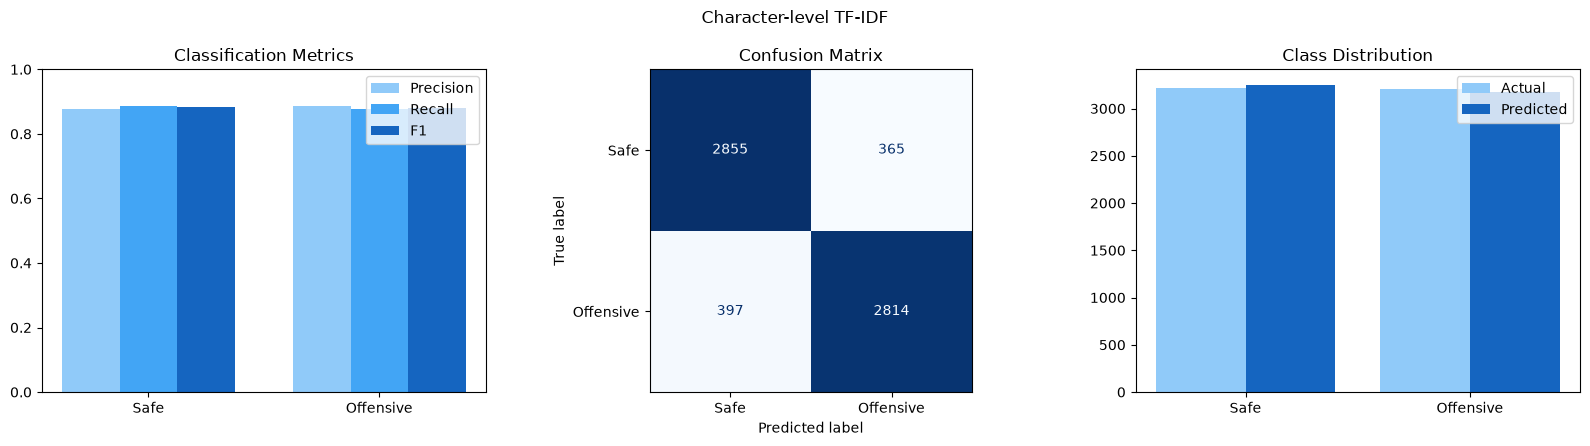

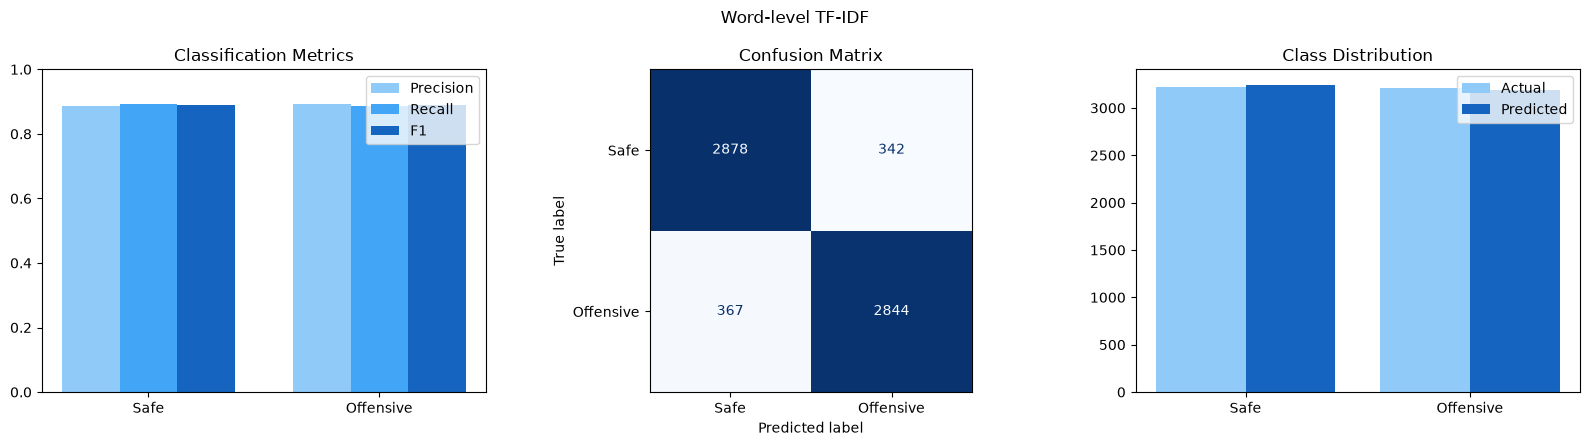

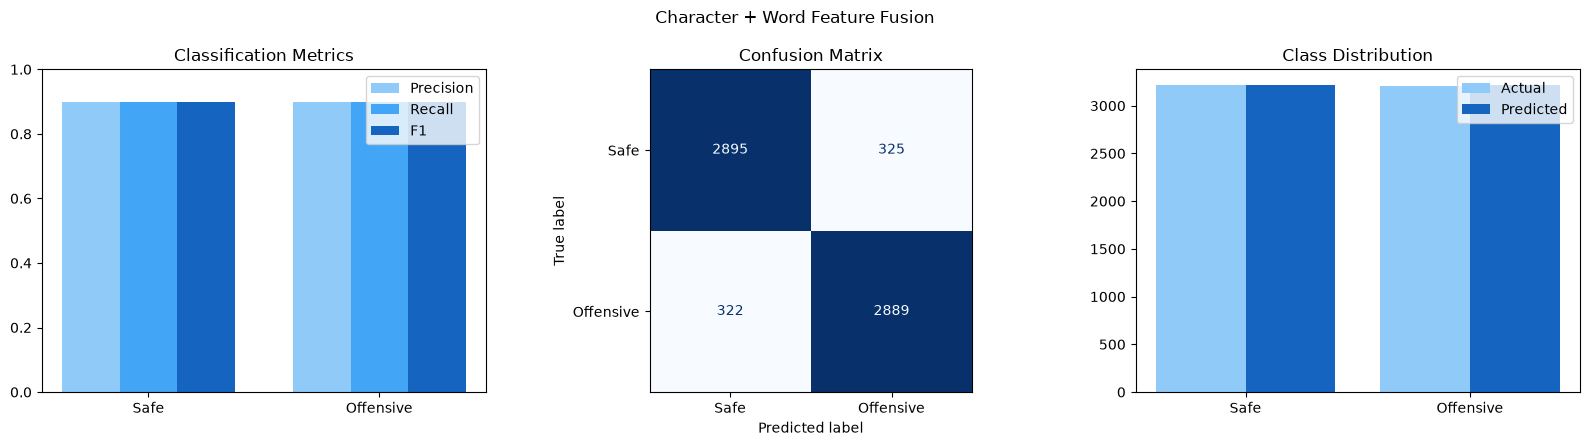

In [55]:
# ==========================================
# Model Visualization - Validation Set
# ==========================================

# 1. Character-level TF-IDF
plot_model_results(
    y_true=y_validation,
    y_pred=char_validation_pred,
    model_name="Character-level TF-IDF"
)

# 2. Word-level TF-IDF
plot_model_results(
    y_true=y_validation,
    y_pred=word_validation_pred,
    model_name="Word-level TF-IDF"
)

# 3. Character + Word Feature Fusion
plot_model_results(
    y_true=y_validation,
    y_pred=fusion_validation_pred,
    model_name="Character + Word Feature Fusion"
)



# Error Analysis - Feature Fusion

In [56]:
# ==========================================
# Error Analysis - Feature Fusion
# ==========================================

# 1. Create Prediction DataFrame
error_df = pd.DataFrame({
    "text": X_validation.reset_index(drop=True),
    "true_label": y_validation.reset_index(drop=True),
    "predicted_label": fusion_validation_pred
})

# 2. Identify Error Types
error_df["error_type"] = "Correct"

# False Positive: Safe -> Offensive
error_df.loc[
    (error_df["true_label"] == 0) &
    (error_df["predicted_label"] == 1),
    "error_type"
] = "False Positive"

# False Negative: Offensive -> Safe
error_df.loc[
    (error_df["true_label"] == 1) &
    (error_df["predicted_label"] == 0),
    "error_type"
] = "False Negative"

# 3. Separate Misclassified Samples
fp_errors = error_df[error_df["error_type"] == "False Positive"]
fn_errors = error_df[error_df["error_type"] == "False Negative"]

print("Error Distribution:")
print(error_df["error_type"].value_counts())

# 4. Display Misclassified Comments
pd.set_option("display.max_colwidth", 200)

print("\nFalse Positive Examples:")
display(fp_errors.sample(n=min(10, len(fp_errors)), random_state=42))

print("\nFalse Negative Examples:")
display(fn_errors.sample(n=min(10, len(fn_errors)), random_state=42))


Error Distribution:
error_type
Correct           5784
False Positive     325
False Negative     322
Name: count, dtype: int64

False Positive Examples:


,text,true_label,predicted_label,error_type
4882,本人山东妹子嫁给上海男人，跟你反过来了。上海男人确实很好，顾家疼老婆，我公婆也特别好，不会歧视外地人。只是我不懂，你为什么连山东两个字都要故意打错？你怎么不打错青岛两个字？,0,1,False Positive
2299,那个 我想说不是所有东北人都这样的(๑￣ ￣๑),0,1,False Positive
5140,没想到时至今日，在这里依然能看到地图炮。。。河南人路过，现居西安，本人表示从来没偷过井盖，对井盖也没有兴趣，也没见过有人去偷井盖。,0,1,False Positive
263,男尊女卑在过去被推崇那不就是因为过去社会看重的是人的体能，而不是因为你想的中国就是个重男轻女的国家，社会需要什么不会因为这个人是男的女的，而是因为这个人具备什么特质。团结你的朋友抗击共同的敌人,0,1,False Positive
1881,我倒是觉得引进黑人没什么问题，中国文化和美国文化本质不同，黑人在中国教育环境下能变成中华黑人，有思想有内涵，再加上黑人能生，黑人和中国女性的结合会十分完美，保留了中华血统的同时还优化了运动基因，,0,1,False Positive
4693,不是说广东人什么都吃吗？明显辣椒不吃啊！,0,1,False Positive
5665,吴芝圃可被河南人民斗死了。,0,1,False Positive
4118,有见地，就像生活中拯救自卑者的方法，如果是一味地保护，鼓励，而非从根本上平等对待他，那么同样是一种歧视。电影里的“反派角色”就像日常工作中的重要职位，只有对“白人”和“黑人”一视同仁，都可做这个反面人设，才是真正的公平。支持。,0,1,False Positive
4230,不要把外地小妹妹吓着呢，以后没人敢嫁到重庆来了,0,1,False Positive
1971,愿美国黑人独立，愿中国黑人去美国黑人独立区享受自由生活,0,1,False Positive



False Negative Examples:


,text,true_label,predicted_label,error_type
3970,我们东北天天睡炕上，我们东北顿顿吃酸菜，我们东北半个月洗次澡。不穿貂好像对不起你家祖宗:),1,0,False Negative
3224,最近很喜欢看女同，看的时候代入感很强，希望自己也是个女生和女生爱爱。,1,0,False Negative
4486,不是黄女受欢迎，而是黄女对比白女的性格属于千依百顺，而且容易泡，亚裔女崇洋媚外的多，受到底层外国男人喜欢，你看看好莱坞明星，nba黑人球员，除了那个破产的凯奇，谁找黄女，不都是白女，NBA黑人有钱都找白女，黄女无人问津。,1,0,False Negative
271,一个朋友，得知其宿舍之前住了个印度人，感到非常恶心，用大量消毒剂打扫房间两天。如果真的有味道，消毒没啥问题吧一个学妹，交了个印度男朋友。其他同学得知此事，背后指责她好贱。这个确实是，,1,0,False Negative
2491,确切点儿说，是不是女生的价值不需要通过媚人来体现？,1,0,False Negative
2958,北方。“我来自北京。”回。“冬天冷死了吧？”,1,0,False Negative
5469,好像可以称呼其小哥哥（爷T）。,1,0,False Negative
3768,看看抖音男性对彩礼的评论:我未来承包了你的后半生，我没找你要抚养费都不错了，你还敢要彩礼？,1,0,False Negative
4841,醒醒，你哪来的女朋友？工头叫你搬砖了！,1,0,False Negative
6257,还有BP一部分粉丝真的无语 微博啥的好多都看不起东南亚粉丝不承认他们的 东南亚人民心里苦啊连粉丝也分国籍了[飙泪笑],1,0,False Negative
